In [104]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from pmdarima import auto_arima

import warnings
warnings.filterwarnings('ignore')

In [105]:
def analyze_weekly(df: pd.DataFrame, col: str):
    """
    Analyze a weekly time series (Friday-indexed) for seasonal variation, variability,
    intra-year price rise, instability (CDVI), stationarity, and ACF/PACF.

    Expects:
      - df.index is a DatetimeIndex at weekly frequency (W-FRI recommended)
      - df[col] contains numeric data
    """

    # ----- Guards & normalization -------------------------------------------------
    if not isinstance(df.index, pd.DatetimeIndex):
        raise TypeError('DataFrame index must be a DatetimeIndex.')

    # Enforce weekly Friday grid (creates missing Fridays as NaN if absent)
    df = df.copy()
    df = df.asfreq('W-FRI')

    # We'll often need week-of-year and year groupers
    iso = df.index.isocalendar()  # DataFrame with .year, .week, .day
    week = iso.week.astype(int)   # 1..53
    year = iso.year.astype(int)

    s = df[col].astype(float)

    # ----- ASPV: Average Seasonal Price Variation (by week-of-year) ---------------
    weekly_avg = s.groupby(week).mean()
    total_avg = s.mean()
    aspv = weekly_avg / total_avg

    # ----- CV: Coefficient of Variation by week-of-year ---------------------------
    weekly_std = s.groupby(week).std()
    weekly_mean = s.groupby(week).mean()
    cv = (weekly_std / weekly_mean).replace([np.inf, -np.inf], np.nan)

    # ----- IPR: Intra-Year Price Rise (mean over years of max/min within year) ----
    yearly_max = s.groupby(year).max()
    yearly_min = s.groupby(year).min()
    ipr = (yearly_max / yearly_min).replace([np.inf, -np.inf], np.nan).mean()

    # ----- CDVI: Cuddy–Della Valle Index (instability) ----------------------------
    # overall CV of series
    total_cv = (s.std() / s.mean()) if s.mean() != 0 else np.nan
    weekly_means = weekly_mean
    cdvi = ((weekly_means.std() / weekly_means.mean()) / total_cv
            if (weekly_means.mean() not in [0, np.nan] and total_cv not in [0, np.nan])
            else np.nan)

    print('Intra Year Price Rise (IPR):', ipr)
    print('Cuddy Della Valle Index (CVDI):', cdvi)

    # ----- Stationarity check (ADF) -----------------------------------------------
    # Use first difference for weekly data (you can add seasonal diff 52 if needed)
    s_diff = s.diff().dropna()
    adf_p = adfuller(s_diff.dropna())[1] if len(s_diff.dropna()) > 0 else np.nan
    print('ADF p-value (after 1st difference):', adf_p)

    # ----- Plots ------------------------------------------------------------------
    # 1) ASPV and CV bars (weeks 1..53)
    weeks = np.arange(1, 54)  # to show all week slots; data may have NaNs for missing weeks

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.bar(weeks, aspv.reindex(weeks))
    plt.title('Average Seasonal Price Variation (ASPV)')
    plt.xlabel('Week of Year')
    plt.ylabel('Relative Level')
    plt.xticks([1, 13, 26, 39, 53])

    plt.subplot(1, 2, 2)
    plt.bar(weeks, cv.reindex(weeks))
    plt.title('Weekly Coefficient of Variation (CV)')
    plt.xlabel('Week of Year')
    plt.ylabel('STD / Mean')
    plt.xticks([1, 13, 26, 39, 53])

    plt.tight_layout()
    # plt.show()

    # 2) ACF / PACF on differenced series
    if s_diff.notna().sum() > 10:
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plot_acf(s_diff.dropna(), lags=40, ax=plt.gca())
        plt.title('ACF (diffed)')

        plt.subplot(1, 2, 2)
        # OLS is fine here as original is likely nonstationary pre-diff
        plot_pacf(s_diff.dropna(), lags=40, ax=plt.gca(), method='ols')
        plt.title('PACF (diffed)')
        plt.tight_layout()
        # plt.show()
    else:
        print('Not enough non-NaN points after differencing to plot ACF/PACF.')

    # ----- auto_arima order suggestion (non-seasonal by default) ------------------
    # If you want seasonal, set seasonal=True, m=52
    try:
        stepwise_model = auto_arima(s, seasonal=False, trace=False, error_action='ignore')
        print('Auto ARIMA order:', stepwise_model.order)
    except Exception as e:
        print('auto_arima failed:', str(e))

def evaluate_forecast(model_name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    mpe = np.mean((actual - predicted) / actual) * 100
    rmspe = np.sqrt(np.mean(np.square((actual - predicted) / actual))) * 100
    ss_res = np.sum((actual - predicted)**2)
    ss_tot = np.sum((actual - actual.mean())**2)
    r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else float('nan')
    acc = 100.0 * (1 - mae / actual.mean()) if actual.mean() != 0 else float('nan')
    
    print(f"\n[{model_name}] test performance:")
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"MSE: {mse:.2f}")
    print(f"MAPE: {mape:.2f}")
    print(f"MPE: {mpe:.2f}")
    print(f"RMSPE: {rmspe:.2f}")
    print(f"R²: {r2:.2f}")
    print(f"Accuracy: {acc:.2f}")

def plot_forecast_intervals(train_data, test_data, forecast_mean, conf_intervals, model_name="Model"):
    """
    Plot training data, test data, forecasts with confidence intervals
    """
    plt.figure(figsize=(15, 8))
    
    # Plot training data
    plt.plot(train_data.index, train_data, label='Training Data', color='blue', alpha=0.8)
    
    # Plot test data
    plt.plot(test_data.index, test_data, label='Actual Test Data', color='green', linewidth=2)
    
    # Plot forecast
    plt.plot(test_data.index, forecast_mean, label='Forecast', color='red', linestyle='--', linewidth=2)
    
    # Plot confidence intervals
    if conf_intervals is not None:
        plt.fill_between(test_data.index,
                        conf_intervals.iloc[:, 0],
                        conf_intervals.iloc[:, 1],
                        color='red', alpha=0.2,
                        label='95% Confidence Interval')
    
    plt.title(f'{model_name} - Forecast vs Actual', fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    return plt.gcf()


In [106]:
file_path = os.path.join('..', 'model_features.csv')
df = pd.read_csv(file_path, index_col=['DATE'])
df.index = pd.to_datetime(df.index)
# df

Intra Year Price Rise (IPR): 1.211870895511211
Cuddy Della Valle Index (CVDI): 0.20839668195466712
ADF p-value (after 1st difference): 5.225738727126438e-24
Auto ARIMA order: (4, 2, 1)


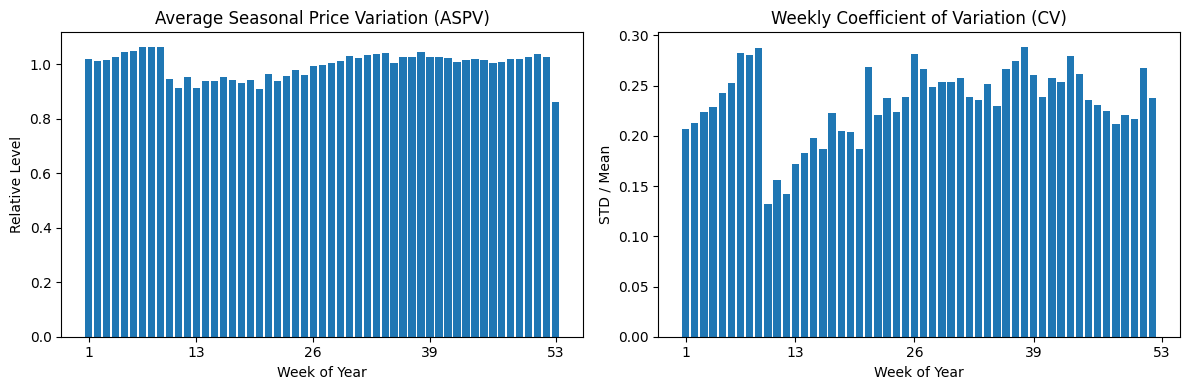

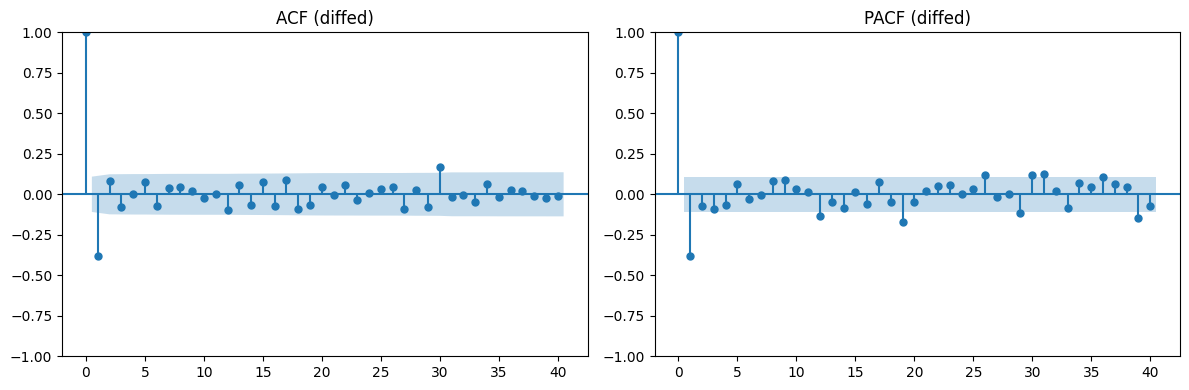

In [107]:
train_analyze = df.iloc[:int(len(df)*0.8)]
analyze_weekly(train_analyze, 'AVG_PRICE_AUCTION')

In [108]:
order = (4, 2, 1)

# do an 80/20 train-test split
df = df['AVG_PRICE_AUCTION']

n = len(df)
train_size = int(n * 0.8)

train = df.iloc[:train_size]
test = df.iloc[train_size:]

model = ARIMA(train, order=order).fit()
print(model.summary())

# Forecast
forecast_results = model.get_forecast(steps=len(test))
forecast = forecast_results.predicted_mean

# Get confidence intervals
confidence_intervals = forecast_results.conf_int(alpha=0.05)  # 95% confidence interval


                               SARIMAX Results                                
Dep. Variable:      AVG_PRICE_AUCTION   No. Observations:                  324
Model:                 ARIMA(4, 2, 1)   Log Likelihood               -1022.224
Date:                Thu, 25 Sep 2025   AIC                           2056.448
Time:                        13:42:16   BIC                           2079.095
Sample:                    12-22-2017   HQIC                          2065.489
                         - 03-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4343      0.047     -9.266      0.000      -0.526      -0.342
ar.L2         -0.1361      0.047     -2.919      0.004      -0.227      -0.045
ar.L3         -0.1344      0.056     -2.417      0.0

In [109]:
evaluate_forecast("ARIMA with Manual Seasonal Differencing", test, forecast)


[ARIMA with Manual Seasonal Differencing] test performance:
MAE: 28.67
RMSE: 32.52
MSE: 1057.85
MAPE: 10.37
MPE: -9.22
RMSPE: 12.09
R²: 0.35
Accuracy: 90.15


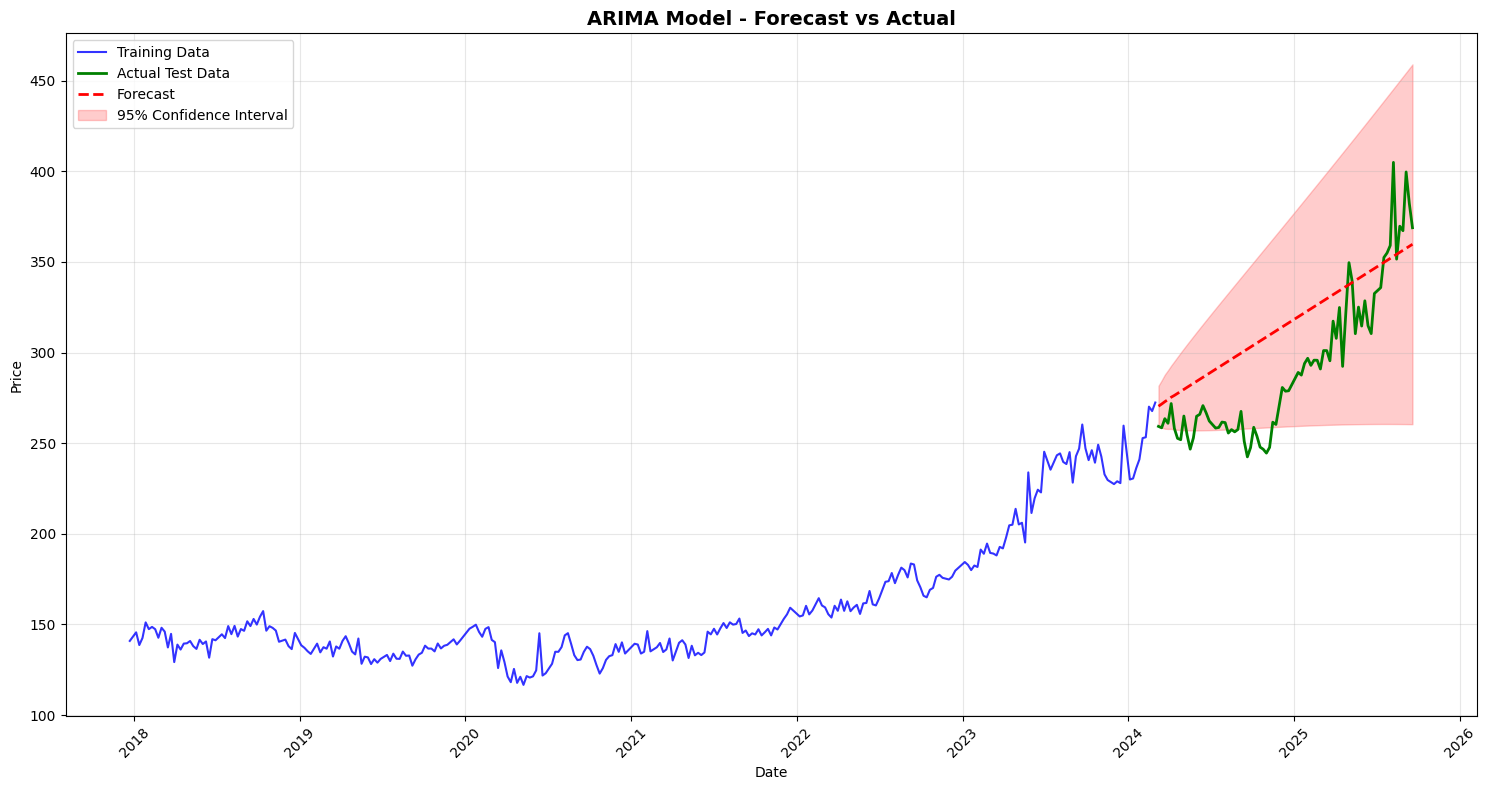

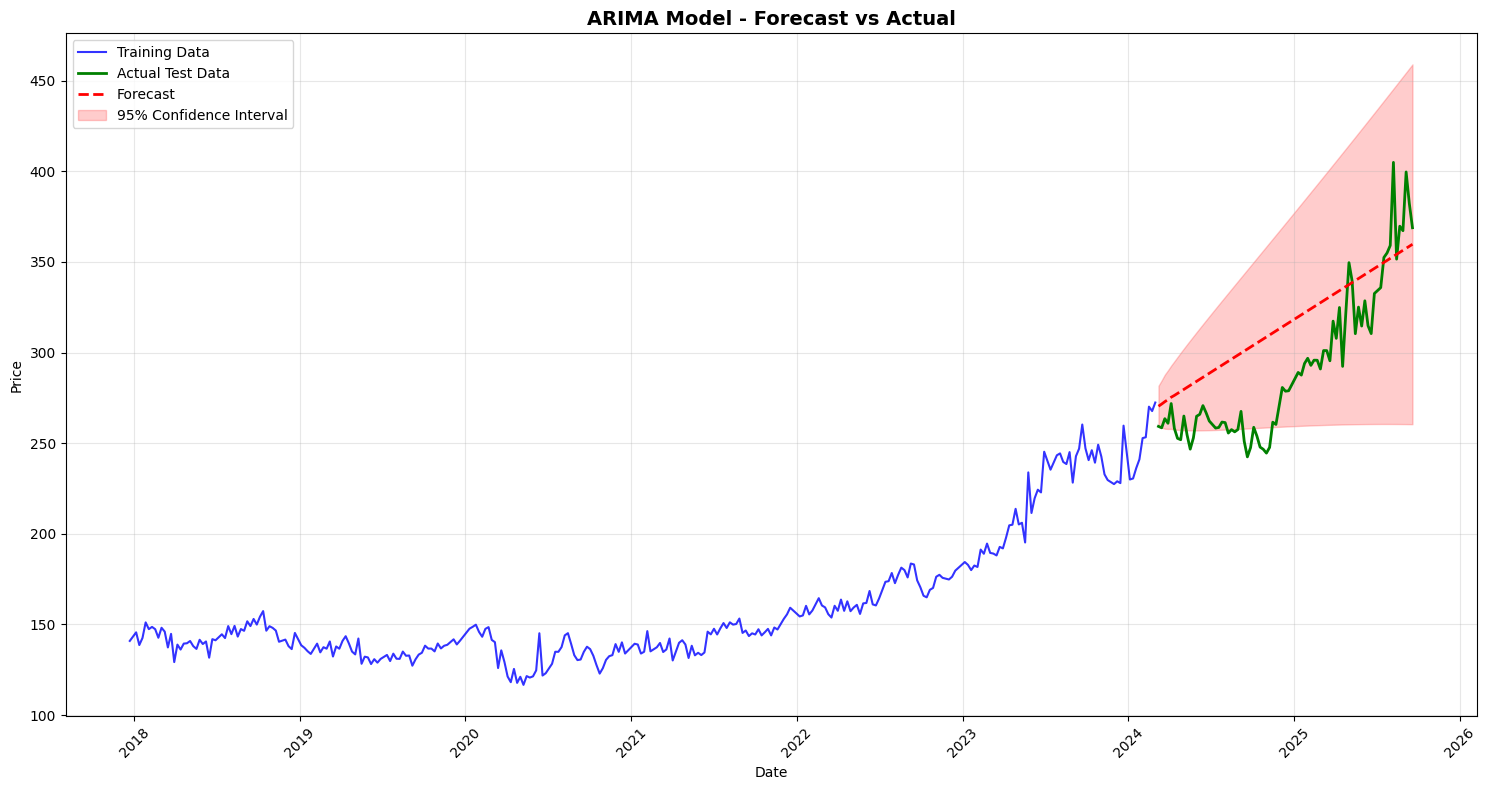

In [110]:
plot_forecast_intervals(train, test, forecast, confidence_intervals, 'ARIMA Model')